### Pyramidal validation: ensure that cell is the same as in hnn-core

This is an unpublished sanity check to ensure that copying the cell properties to hnn-core was successful.
Slight deviations (order 1e-10) likely due to slight differences in calculating segments.

In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt

import sys

import neuron
from neuron import h
import hnn_core

from hnn_core import duecker_ET_model, simulate_dipole
from hnn_tuning.l23_plot_utils import get_l2pyr
from hnn_tuning.l5_plot_utils import get_l5pyr
from scipy.signal import find_peaks

import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
from hnn_tuning import SINGLE_CELL_SIM, HNN_CORE_MOD
pth_mod = str(HNN_CORE_MOD)
pathfig = str(SINGLE_CELL_SIM / 'figures')

#### L2/3

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Duecker model baseline correction


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/network.py:586: UserWarning: Zero distance between cells of type 'L2_inhibitory' in the X dimension in the provided 'pos_dict'. 
This can happen if: 
- you are simulating a network with only a single cell of this cell type, e.g. using `mesh_shape=(1, 1)`.
- the positions of 'L2_inhibitory' in your 'pos_dict' are all the same in the X dimension. 
If this is not intentional, check your 'pos_dict'!
  warnings.warn(
/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/network.py:586: UserWarning: Zero distance between cells of type 'L2_inhibitory' in the Y dimension in the provided 'pos_dict'. 
This can happen if: 
- you are simulating a network with only a single cell of this cell type, e.g. using `mesh_shape=(1, 1)`.
- the positions of 'L2_inhibitory' in your 'pos_dict' are all the same in the Y dimension. 
If this is not intentional, check your 'pos_dict'!
  warnings.warn(
/Users/katha

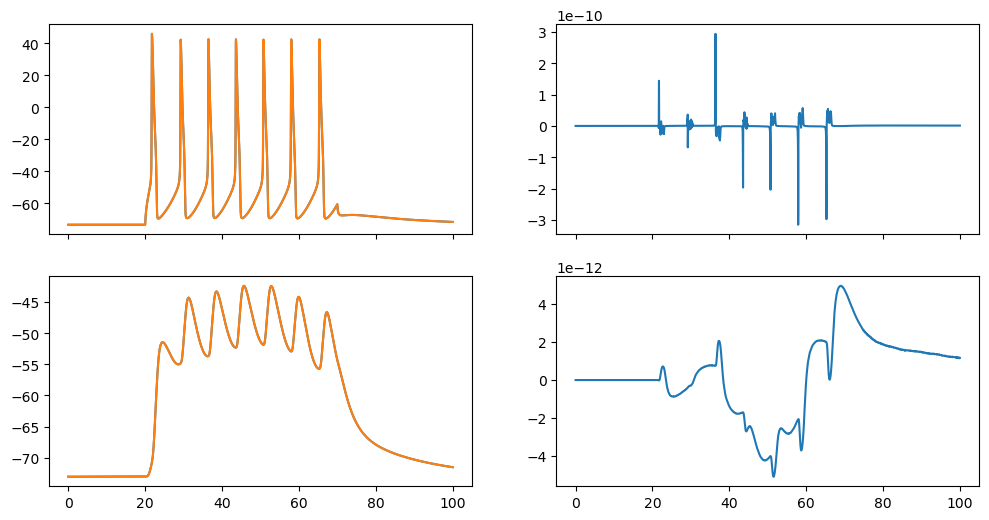

In [2]:
h.nrnunit_use_legacy(1)
l2pyr = get_l2pyr()


stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 50
stim.amp = 2

t = h.Vector().record(h._ref_t)

soma_voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)
apical_voltg = h.Vector().record(l2pyr._nrn_sections['apical_tuft'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(100)

v_np = soma_voltg.to_python()
a_np = apical_voltg.to_python()

distance_apical = []
gbar_Ih_apical = []
gbar_Ca_HVA_apical = []
gbar_Ca_LVA_apical = []
gbar_SK_E2_apical = []

apical_sections=['apical_trunk', 'apical_1', 'apical_tuft']
h.distance(sec = l2pyr._nrn_sections['soma'])
for section in apical_sections:
    for seg in l2pyr._nrn_sections[section]:
        distance_apical.append(h.distance(seg.x, sec=seg.sec))
        gbar_Ih_apical.append(seg.gbar_Ih_hay2011)
        gbar_Ca_HVA_apical.append(seg.gbar_Ca_HVA_hay2011)
        gbar_Ca_LVA_apical.append(seg.gbar_Ca_LVAst_hay2011)
        gbar_SK_E2_apical.append(seg.gbar_SK_E2_hay2011)


h('forall delete_section()')
# HNN
net = duecker_ET_model(mesh_shape=(1,1))
net.clear_connectivity()
net.add_tonic_bias(cell_type='L2_pyramidal', section='soma', bias_name='clamp', amplitude=2, t0=20, tstop = 70)
dpl = simulate_dipole(net, tstop=100,record_vsec='all', record_ca='all', record_isec='all', bsl_cor="duecker")


fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
ax[0,0].plot(t, v_np, label='NEURON')
ax[0,0].plot(net.cell_response.times, net.cell_response.vsec[0][1]['soma'], label='HNN')
ax[0,1].plot(t, np.array(v_np)-np.array(net.cell_response.vsec[0][1]['soma']), label='Difference')
#ax[0,1].set_xlim((15, 35))
ax[1,0].plot(t, a_np, label='NEURON')
ax[1,0].plot(net.cell_response.times, net.cell_response.vsec[0][1]['apical_tuft'], label='HNN')
ax[1,1].plot(t, np.array(a_np)-np.array(net.cell_response.vsec[0][1]['apical_tuft']), label='Difference')

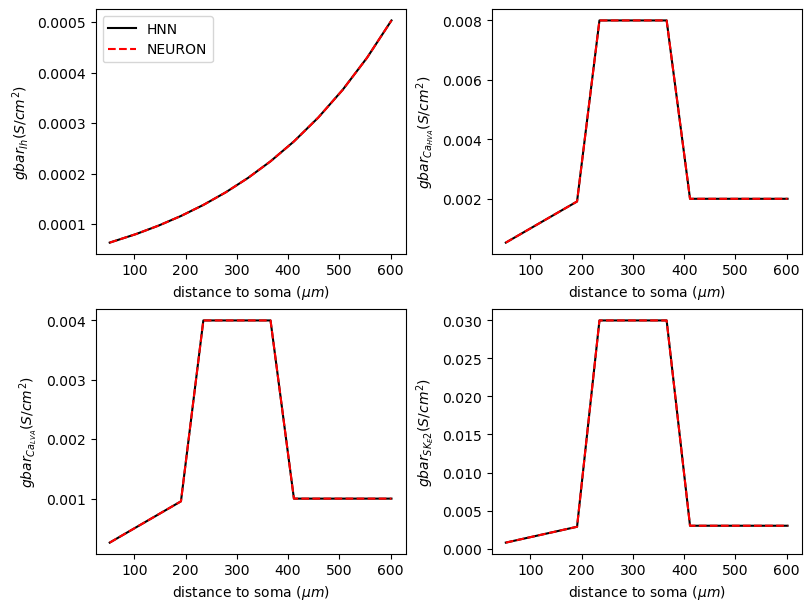

In [3]:
# compare conductances
L = net.cell_types['L2_pyramidal']['cell_object'].sections['soma'].L
distance_HNN = []
Ih = []
CHVA = []
CLVA = []

apical_sections=['apical_trunk', 'apical_1', 'apical_tuft']
for section in apical_sections:
    for s, seg in enumerate(net.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][0]):
        distance_HNN.append(float(L+net.cell_types['L2_pyramidal']['cell_object'].sections[section].L*seg))
        Ih.append(net.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ih_hay2011']['gbar_Ih_hay2011'][1][s])
        CHVA.append(net.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][1][s])
        CLVA.append(net.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst_hay2011']['gbar_Ca_LVAst_hay2011'][1][s])

    L += net.cell_types['L2_pyramidal']['cell_object'].sections[section].L


fig, ax = plt.subplots(2,2, figsize=(8, 6), constrained_layout=True)
ax =ax.flatten()
ax[0].plot(distance_HNN, Ih, color='k', label='HNN')
ax[0].plot(distance_apical, gbar_Ih_apical, color='r', linestyle='--', label='NEURON')
ax[0].set_ylabel(r'$gbar_{Ih} (S/cm^2)$')
ax[0].set_xlabel(r'distance to soma ($\mu m$)')
ax[1].plot(distance_HNN, CHVA, color='k', label='HNN')
ax[1].plot(distance_apical, gbar_Ca_HVA_apical, color='r', linestyle='--', label='NEURON')
ax[1].set_ylabel(r'$gbar_{Ca_{HVA}} (S/cm^2)$')
ax[1].set_xlabel(r'distance to soma ($\mu m$)')
ax[2].plot(distance_HNN, CLVA, color='k', label='HNN')
ax[2].plot(distance_apical, gbar_Ca_LVA_apical, color='r', linestyle='--', label='NEURON')
ax[2].set_ylabel(r'$gbar_{Ca_{LVA}} (S/cm^2)$')
ax[2].set_xlabel(r'distance to soma ($\mu m$)')

ax[3].plot(distance_HNN, gbar_SK_E2_apical, color='k', label='HNN')
ax[3].plot(distance_apical, gbar_SK_E2_apical, color='r', linestyle='--', label='NEURON')
ax[3].set_ylabel(r'$gbar_{SK_E2} (S/cm^2)$')
ax[3].set_xlabel(r'distance to soma ($\mu m$)')
ax[0].legend()


#### L5

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod.  Aborting.
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Applying Duecker model baseline correction


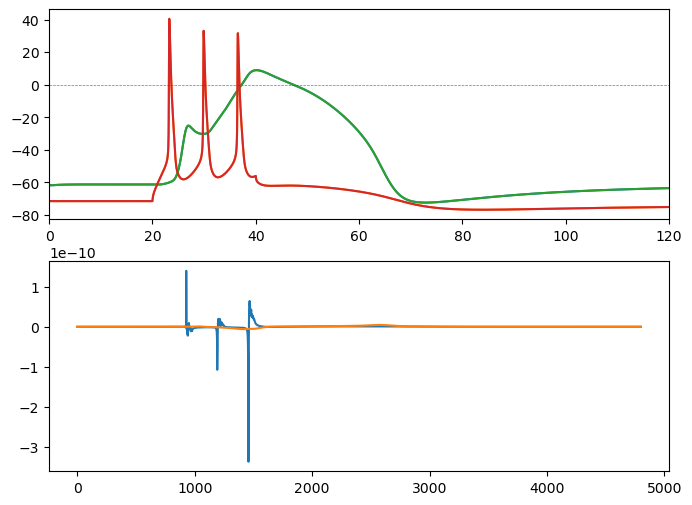

In [4]:
l5pyr = get_l5pyr()

voltg = [None]*2
t = h.Vector().record(h._ref_t)
stim = h.IClamp(l5pyr._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 20
stim.amp = 3


voltg[1] = h.Vector().record(l5pyr._nrn_sections['soma'](0.5)._ref_v)

voltg[0] = h.Vector().record(l5pyr._nrn_sections['apical_tuft'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(120)

clamp_current = np.zeros_like(t.as_numpy())
clamp_current[(t.as_numpy() > stim.delay) & (t.as_numpy() < stim.delay+stim.dur)] = stim.amp

v_soma = voltg[1].as_numpy().copy()
v_apcl = voltg[0].as_numpy().copy()

distance_apical = []
gbar_Ih_apical = []
gbar_Ca_HVA_apical = []
gbar_Ca_LVA_apical = []

apical_sections=['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
h.distance(sec = l5pyr._nrn_sections['soma'])
for section in apical_sections:
    for seg in l5pyr._nrn_sections[section]:
        distance_apical.append(h.distance(seg.x, sec=seg.sec))
        gbar_Ih_apical.append(seg.gbar_Ih_hay2011)
        gbar_Ca_HVA_apical.append(seg.gbar_Ca_HVA_hay2011)
        gbar_Ca_LVA_apical.append(seg.gbar_Ca_LVAst_hay2011)

h('forall delete_section()')

net = duecker_ET_model(mesh_shape=(1,1))
net.clear_connectivity()
net.add_tonic_bias(cell_type='L5_pyramidal', section='soma', bias_name='clamp', amplitude=3, t0=20, tstop = 40)
dpl = simulate_dipole(net, tstop=120, bsl_cor='duecker', record_vsec='all', record_ca='all', record_isec='all')


fig, ax = plt.subplots(2, 1, figsize=(8, 6))

for s, section in enumerate(['apical_2', 'soma']):
    ax[0].axhline(y=0, color='black', alpha=0.2, linewidth=0.5, linestyle='--')
    ax[0].plot(t, voltg[s])
ax[0].plot(np.array(net.cell_response.times), np.array(net.cell_response.vsec[0][3]['apical_tuft']))
ax[0].plot(np.array(net.cell_response.times), np.array(net.cell_response.vsec[0][3]['soma']))
ax[0].axhline(y=0, color='black', alpha=0.2, linewidth=0.5, linestyle='--')
ax[0].set_xlim((0, 120))

ax[1].plot(np.array(net.cell_response.vsec[0][3]['soma'])-v_soma)
ax[1].plot(np.array(net.cell_response.vsec[0][3]['apical_tuft'])-v_apcl)

<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:28: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_77191/1800864190.py:24: SyntaxWarning: invalid escape sequence '\m'
  ax[0].set_xlabel('distance to soma ($\mu m$)')
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_77191/1800864190.py:28: SyntaxWarning: invalid escape sequence '\m'
  ax[1].set_xlabel('distance to soma ($\mu m$)')
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_77191/1800864190.py:32: SyntaxWarning: invalid escape sequence '\m'
  ax[2].set_xlabel('distance to soma ($\mu m$)')


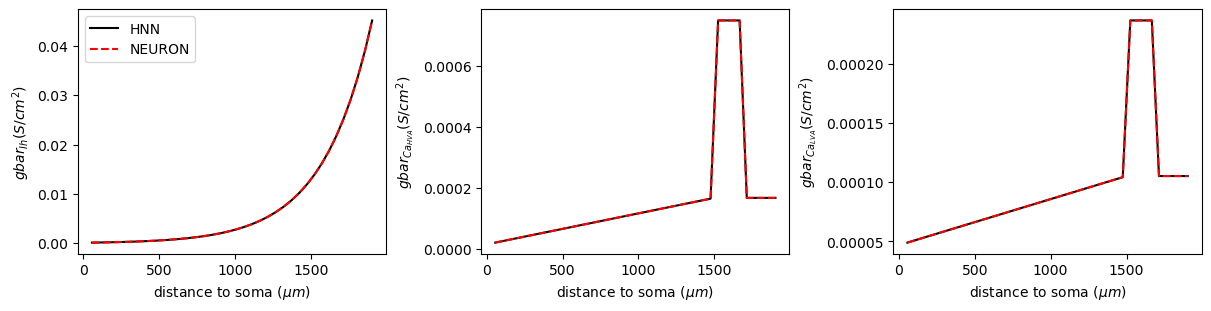

In [5]:
# compare conductances

L = net.cell_types['L5_pyramidal']['cell_object'].sections['soma'].L
distance_HNN = []
Ih = []
CHVA = []
CLVA = []

apical_sections=['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
for section in apical_sections:
    for s, seg in enumerate(net.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][0]):
        distance_HNN.append(float(L+net.cell_types['L5_pyramidal']['cell_object'].sections[section].L*seg))
        Ih.append(net.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ih_hay2011']['gbar_Ih_hay2011'][1][s])
        CHVA.append(net.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][1][s])
        CLVA.append(net.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst_hay2011']['gbar_Ca_LVAst_hay2011'][1][s])

    L += net.cell_types['L5_pyramidal']['cell_object'].sections[section].L


fig, ax = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
ax[0].plot(distance_HNN, Ih, color='k', label='HNN')
ax[0].plot(distance_apical, gbar_Ih_apical, color='r', linestyle='--', label='NEURON')
ax[0].set_ylabel('$gbar_{Ih} (S/cm^2)$')
ax[0].set_xlabel('distance to soma ($\mu m$)')
ax[1].plot(distance_HNN, CHVA, color='k', label='HNN')
ax[1].plot(distance_apical, gbar_Ca_HVA_apical, color='r', linestyle='--', label='NEURON')
ax[1].set_ylabel('$gbar_{Ca_{HVA}} (S/cm^2)$')
ax[1].set_xlabel('distance to soma ($\mu m$)')
ax[2].plot(distance_HNN, CLVA, color='k', label='HNN')
ax[2].plot(distance_apical, gbar_Ca_LVA_apical, color='r', linestyle='--', label='NEURON')
ax[2].set_ylabel('$gbar_{Ca_{LVA}} (S/cm^2)$')
ax[2].set_xlabel('distance to soma ($\mu m$)')
ax[0].legend()
